In [21]:
#Imports necesarios
import os

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from ipywidgets import FloatSlider, interact
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

#Se establecen parametros fijos para las visualizaciones
AZUL, NARANJA, VERDE, GRIS, TINTA = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984", "#0b0b0b"
SALIDA = "figuras"
os.makedirs(SALIDA, exist_ok=True)
plt.rcParams.update({
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "xtick.color": "#52514e",
    "ytick.color": "#52514e", "axes.grid": True, "grid.color": "#e8e7e2",
    "grid.linewidth": 0.7, "legend.frameon": False, "lines.linewidth": 2,
    "savefig.dpi": 200, "savefig.bbox": "tight", "figure.facecolor": "white",
})
L = 2 * np.pi  #valor de x = kr cuando r = lambda
REGIONES = [
    ("Región cercana: $r \\ll \\lambda$", 0.05),
    ("Intermedia: $r \\sim \\lambda/2\\pi$", 0.5),
    ("Región de radiación: $r \\gg \\lambda$", 4.0),
]

#Se define una utilidad para guardar las figuras
def guardar(fig, nombre):
    fig.savefig(os.path.join(SALIDA, nombre))
    plt.show()

In [22]:
## Soluciones analiticas ## 
#Unidades: x = kr, wt = fase temporal, tau = wt - x,
#E0 = p0 k^3/(4 pi eps0), B0 = E0/c, S0 = E0^2/(mu0 c).
#Salen de los potenciales de Griffiths 11.12 y 11.17.

def campos(x, th, wt):
    """Devuelve (E_r, E_th, cB_ph) en unidades de E0."""
    tau = wt - x
    C, Sn = np.cos(tau), np.sin(tau)
    E_r = 2 * np.cos(th) * (C / x**3 - Sn / x**2)
    E_th = np.sin(th) * (C / x**3 - Sn / x**2 - C / x)
    cB_ph = -np.sin(th) * (C / x + Sn / x**2)
    return E_r, E_th, cB_ph

def campos_radiacion(x, th, wt):
    """Solo los términos 1/r: Griffiths 11.18 y 11.19."""
    C = np.cos(wt - x)
    return 0 * x, -np.sin(th) * C / x, -np.sin(th) * C / x

def poynting(x, th, wt):
    """S/S0 instantáneo: S_r = E_th cB_ph, S_th = -E_r cB_ph."""
    E_r, E_th, cB_ph = campos(x, th, wt)
    return E_th * cB_ph, -E_r * cB_ph

def poynting_promedio(x, th, n=720):
    """<S>/S0 promediando S(t) numéricamente sobre un periodo."""
    S_r, S_th = 0.0, 0.0
    for wt in 2 * np.pi * np.arange(n) / n:
        a, b = poynting(x, th, wt)
        S_r, S_th = S_r + a, S_th + b
    return S_r / n, S_th / n

def poynting_promedio_exacto(x, th):
    """<S_r>/S0 = sin^2(th)/(2 x^2); equivale a Griffiths 11.21."""
    return np.sin(th) ** 2 / (2 * x**2)

def potencia_esfera(x, wt):
    """P(r,t)/<P> por una esfera de radio r (integral angular analítica)."""
    return 2 * x**2 * poynting(x, np.pi / 2, wt)[0]

def fasores(x, th=np.pi / 2):
    """Fasores (E_th, cB_ph), con f(t) = Re[f exp(i tau)]."""
    return np.sin(th) * (1 / x**3 + 1j / x**2 - 1 / x), -np.sin(th) * (1 / x - 1j / x**2)

def funcion_lineas_E(x, th, wt):
    """Las curvas Psi = cte son exactamente las líneas de E."""
    tau = wt - x
    return np.sin(th) ** 2 * (np.cos(tau) / x - np.sin(tau))

def triada(x, th):
    """Vectores E, cB y S en coordenadas (x, y, z), en el instante de máximo E_th."""
    fases = np.linspace(0, 2 * np.pi, 1441)
    w = fases[np.argmax(np.abs(campos(x, th, fases)[1]))]
    Er, Et, B = campos(x, th, w)
    Sr, St = poynting(x, th, w)
    rh = np.array([np.sin(th), 0, np.cos(th)])
    tt = np.array([np.cos(th), 0, -np.sin(th)])
    return Er * rh + Et * tt, B * np.array([0, 1, 0]), Sr * rh + St * tt, rh

### Verificación de las ecuaciones
Ejecuta pruebas sobre las funciones anteriores: las ecuaciones de Maxwell, los límites $r \ll \lambda$ y $r \gg \lambda$, el promedio de $\mathbf{S}$ y la potencia total.

In [23]:
#Claude AI recomienda un scrip de verificacion lo cual resulta interesante:
def verificar():
    fallos = 0

    def prueba(nombre, valor, tol):
        nonlocal fallos
        ok = bool(valor < tol)
        fallos += not ok
        print(f"[{'OK ' if ok else 'FALLA'}] {nombre}: {valor:.3e} (tol {tol:.0e})")

    x, th, wt = sp.symbols("x theta wt", positive=True)
    tau = wt - x
    Er = 2 * sp.cos(th) * (sp.cos(tau) / x**3 - sp.sin(tau) / x**2)
    Eth = sp.sin(th) * (sp.cos(tau) / x**3 - sp.sin(tau) / x**2 - sp.cos(tau) / x)
    cB = -sp.sin(th) * (sp.cos(tau) / x + sp.sin(tau) / x**2)
    maxwell = {
        "Gauss": sp.diff(x**2 * Er, x) / x**2 + sp.diff(sp.sin(th) * Eth, th) / (x * sp.sin(th)),
        "Faraday (phi)": (sp.diff(x * Eth, x) - sp.diff(Er, th)) / x + sp.diff(cB, wt),
        "Ampere-Maxwell (r)": sp.diff(sp.sin(th) * cB, th) / (x * sp.sin(th)) - sp.diff(Er, wt),
        "Ampere-Maxwell (theta)": -sp.diff(x * cB, x) / x - sp.diff(Eth, wt),
    }
    for nombre, expr in maxwell.items():
        r = sp.simplify(expr)
        print(f"[{'OK ' if r == 0 else 'FALLA'}] {nombre}: residuo simbólico = {r}")
        fallos += r != 0

    f = sp.lambdify((x, th, wt), (Er, Eth, cB), "numpy")
    g = np.random.default_rng(1)
    X, T, W = g.uniform(0.05, 50, 2000), g.uniform(0.01, 3.13, 2000), g.uniform(0, 7, 2000)
    err = max(np.max(np.abs(a - b) / (np.abs(b) + 1e-12)) for a, b in zip(campos(X, T, W), f(X, T, W)))
    prueba("campos() vs. expresión simbólica", err, 1e-6)

    _, Et, B = campos(1000.0, 1.0, 0.3)
    _, Etr, Br = campos_radiacion(1000.0, 1.0, 0.3)
    prueba("E_th -> Griffiths 11.18", abs(Et - Etr) / (np.sin(1.0) / 1000), 2e-3)
    prueba("cB_ph -> Griffiths 11.19", abs(B - Br) / (np.sin(1.0) / 1000), 2e-3)

    Er0, Et0, _ = campos(1e-3, 0.7, 0.0)
    prueba("E_r -> dipolo estático", abs(Er0 * 1e-9 / (2 * np.cos(0.7)) - 1), 1e-5)
    prueba("E_th -> dipolo estático", abs(Et0 * 1e-9 / np.sin(0.7) - 1), 1e-5)

    for x0 in [0.3, 1.0, 30.0]:
        Sr, St = poynting_promedio(x0, 1.1)
        ex = poynting_promedio_exacto(x0, 1.1)
        prueba(f"<S_r> exacto, x = {x0}", abs(Sr / ex - 1), 1e-8)
        prueba(f"<S_th> = 0, x = {x0}", abs(St / ex), 1e-8)

    mu0, c, p0, w = 4e-7 * np.pi, 299792458.0, 1e-9, 2 * np.pi * 1e8
    eps0, k = 1 / (mu0 * c**2), w / c
    E0 = p0 * k**3 / (4 * np.pi * eps0)
    S0 = E0**2 / (mu0 * c)
    prueba("dP/dOmega máx. vs. 11.21", abs(S0 / (2 * k**2) / (mu0 * p0**2 * w**4 / (32 * np.pi**2 * c)) - 1), 1e-12)
    prueba("potencia total vs. 11.22", abs((S0 / k**2) * 4 * np.pi / 3 / (mu0 * p0**2 * w**4 / (12 * np.pi * c)) - 1), 1e-12)

    fases = 2 * np.pi * np.arange(720) / 720
    for x0 in [0.1, 1.0, 30.0]:
        prueba(f"<P> independiente de r, x = {x0}", abs(np.mean(potencia_esfera(x0, fases)) - 1), 1e-8)

    h, X0, T0, W0 = 1e-5, 2.3, 0.9, 0.7
    dPt = (funcion_lineas_E(X0, T0 + h, W0) - funcion_lineas_E(X0, T0 - h, W0)) / (2 * h)
    dPx = (funcion_lineas_E(X0 + h, T0, W0) - funcion_lineas_E(X0 - h, T0, W0)) / (2 * h)
    Er1, Et1, _ = campos(X0, T0, W0)
    prueba("E_r desde Psi", abs(dPt / (X0**2 * np.sin(T0)) / Er1 - 1), 1e-7)
    prueba("E_th desde Psi", abs(-dPx / (X0 * np.sin(T0)) / Et1 - 1), 1e-7)
    print("\nTODO BIEN" if not fallos else f"\n{fallos} PRUEBAS FALLARON")


verificar()

[OK ] Gauss: residuo simbólico = 0
[OK ] Faraday (phi): residuo simbólico = 0
[OK ] Ampere-Maxwell (r): residuo simbólico = 0
[OK ] Ampere-Maxwell (theta): residuo simbólico = 0
[OK ] campos() vs. expresión simbólica: 4.622e-15 (tol 1e-06)
[OK ] E_th -> Griffiths 11.18: 6.245e-04 (tol 2e-03)
[OK ] cB_ph -> Griffiths 11.19: 6.238e-04 (tol 2e-03)
[OK ] E_r -> dipolo estático: 5.000e-07 (tol 1e-05)
[OK ] E_th -> dipolo estático: 5.000e-07 (tol 1e-05)
[OK ] <S_r> exacto, x = 0.3: 9.992e-16 (tol 1e-08)
[OK ] <S_th> = 0, x = 0.3: 6.332e-15 (tol 1e-08)
[OK ] <S_r> exacto, x = 1.0: 4.441e-16 (tol 1e-08)
[OK ] <S_th> = 0, x = 1.0: 4.993e-16 (tol 1e-08)
[OK ] <S_r> exacto, x = 30.0: 2.220e-16 (tol 1e-08)
[OK ] <S_th> = 0, x = 30.0: 1.720e-18 (tol 1e-08)
[OK ] dP/dOmega máx. vs. 11.21: 2.220e-16 (tol 1e-12)
[OK ] potencia total vs. 11.22: 2.220e-16 (tol 1e-12)
[OK ] <P> independiente de r, x = 0.1: 8.082e-14 (tol 1e-08)
[OK ] <P> independiente de r, x = 1.0: 0.000e+00 (tol 1e-08)
[OK ] <P> indepe

Esencialmente, esta celda confirma que las ecuaciones físicas están bien implementadas, un error, como un signo incorrecto, podría generar gráficas “bonitas” sin que el programa falle. Para descartarlo, se comprueba que los campos cumplen las ecuaciones de Maxwell y que recuperan los límites conocidos (dipolo estático y ecs. 11.18–11.22 de Griffiths). 

### Instante de la simulación
Define la fase $\omega t$ que usan las figuras de campos instantáneos.

In [24]:
#Fase en radianes
WT = 0.0 

### Importancia de cada término según la distancia
Grafica las amplitudes $1/(kr)^3$, $1/(kr)^2$ y $1/(kr)$ de $E_\theta$. Permite ver cuál domina en cada región y que las tres coinciden en $r = \lambda/2\pi$.

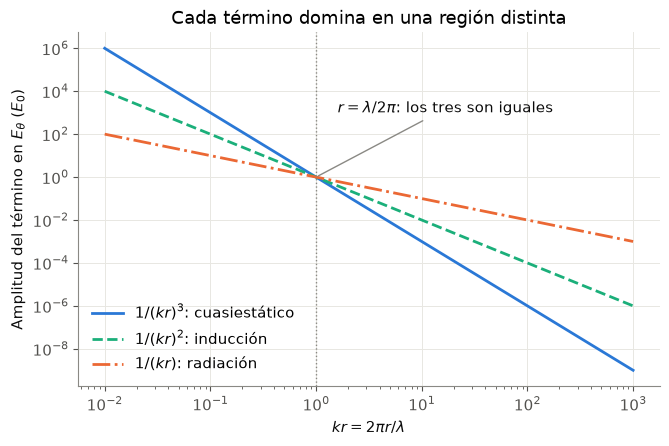

In [25]:
x = np.logspace(-2, 3, 500)
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.loglog(x, 1 / x**3, color=AZUL, label="$1/(kr)^3$: cuasiestático")
ax.loglog(x, 1 / x**2, color=VERDE, ls="--", label="$1/(kr)^2$: inducción")
ax.loglog(x, 1 / x, color=NARANJA, ls="-.", label="$1/(kr)$: radiación")
ax.axvline(1, color=GRIS, lw=1, ls=":")
ax.annotate("$r=\\lambda/2\\pi$: los tres son iguales", (1, 1), (1.6, 1e3), color=TINTA,
            arrowprops=dict(arrowstyle="-", color=GRIS))
ax.set(xlabel="$kr = 2\\pi r/\\lambda$", ylabel="Amplitud del término en $E_\\theta$ ($E_0$)",
       title="Cada término domina en una región distinta")
ax.legend(loc="lower left")
guardar(fig, "01_terminos_vs_r.png")

### Perfil radial de los campos
Compara, en el ecuador ($\theta = 90°$), la solución completa con el término de radiación $1/r$. Las curvas están multiplicadas por $kr$ para que la amplitud lejana se vea constante.

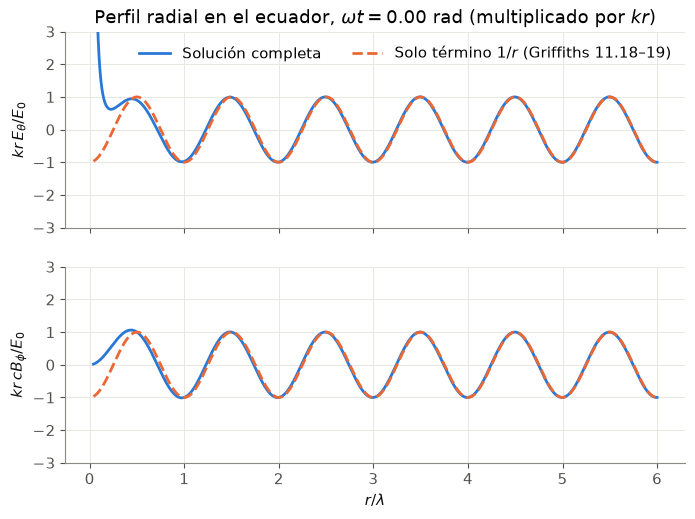

In [26]:
x = np.linspace(0.25, 6 * L, 2400)
_, Et, B = campos(x, np.pi / 2, WT)
_, Etr, Br = campos_radiacion(x, np.pi / 2, WT)
fig, axs = plt.subplots(2, 1, figsize=(8, 5.6), sharex=True)
for ax, y, yr, nom in zip(axs, (Et, B), (Etr, Br), ("$kr\\,E_\\theta/E_0$", "$kr\\,cB_\\phi/E_0$")):
    ax.plot(x / L, x * y, color=AZUL, label="Solución completa")
    ax.plot(x / L, x * yr, color=NARANJA, ls="--", label="Solo término $1/r$ (Griffiths 11.18–19)")
    ax.set_ylim(-3, 3)
    ax.set_ylabel(nom)
axs[0].legend(loc="upper right", ncol=2)
axs[0].set_title(f"Perfil radial en el ecuador, $\\omega t={WT:.2f}$ rad (multiplicado por $kr$)")
axs[1].set_xlabel("$r/\\lambda$")
guardar(fig, "02_perfil_radial.png")

### Mapas de $\mathbf{E}$ y $\mathbf{B}$
Muestra el plano $y=0$ en las regiones cercana, intermedia y de radiación. Las curvas negras son las líneas de $\mathbf{E}$ y el color representa $B$. Cada panel usa su propia escala.

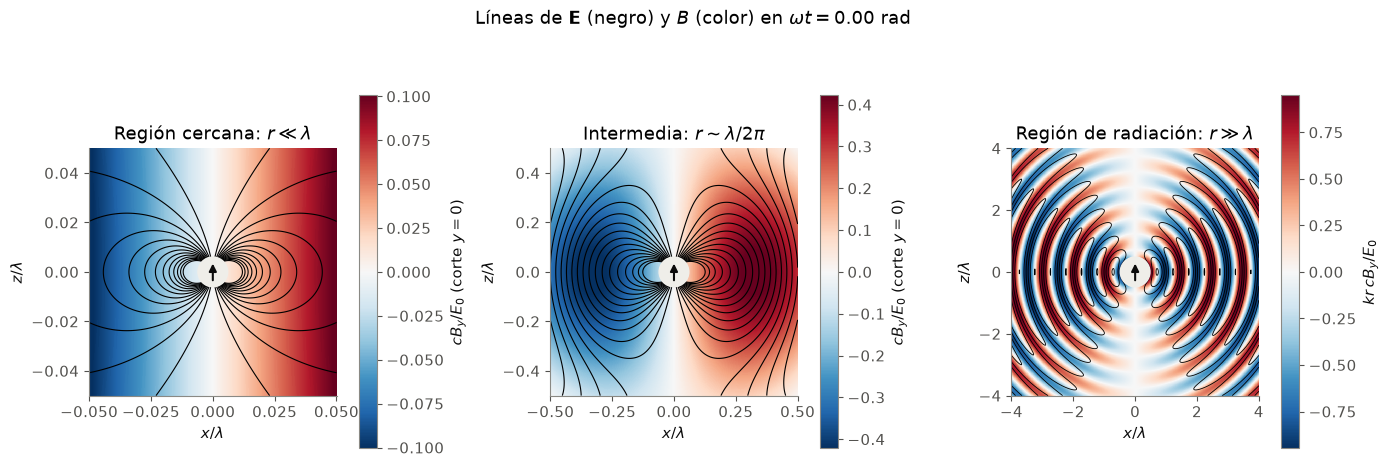

In [27]:
fig, axs = plt.subplots(1, 3, figsize=(14, 5.1))
for ax, (titulo, R) in zip(axs, REGIONES):
    g = np.linspace(-R, R, 700)
    P, Z = np.meshgrid(g, g)
    r = np.hypot(P, Z)
    rmin = 0.12 * R
    x = L * np.where(r < rmin, rmin, r)
    th = np.arctan2(np.abs(P), Z)
    cB = campos(x, th, WT)[2] * (np.sign(P) + (P == 0))  # phi-hat = -y para x < 0
    lejano = R > 1
    if lejano:
        cB = cB * x  # compensa el decaimiento 1/r
    Bplot = np.ma.masked_where(r < rmin, cB)
    vmax = np.percentile(np.abs(Bplot.compressed()), 97)
    im = ax.pcolormesh(P, Z, Bplot, cmap="RdBu_r", vmin=-vmax, vmax=vmax, shading="auto", rasterized=True)
    fig.colorbar(im, ax=ax, shrink=0.8, pad=0.07).set_label(
        "$kr\\,cB_y/E_0$" if lejano else "$cB_y/E_0$ (corte $y=0$)")
    Psi = np.ma.masked_where(r < rmin, funcion_lineas_E(x, th, WT))
    mx = 1.0 if lejano else np.percentile(np.abs(Psi.compressed()), 99)
    niveles = np.linspace(-mx, mx, 6 if lejano else 26)
    niveles = niveles[np.abs(niveles) > 1e-9]
    ax.contour(P, Z, Psi, levels=niveles, colors="k", linewidths=0.6 if lejano else 0.8, linestyles="solid")
    ax.add_patch(plt.Circle((0, 0), rmin, color="#efeee9", zorder=3))
    ax.annotate("", (0, 0.09 * R), (0, -0.09 * R), zorder=4, arrowprops=dict(arrowstyle="-|>", color=TINTA, lw=1.5))
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set(title=titulo, xlabel="$x/\\lambda$", ylabel="$z/\\lambda$")
    ax.set_xticks([-R, -R / 2, 0, R / 2, R])
fig.suptitle(f"Líneas de $\\mathbf{{E}}$ (negro) y $B$ (color) en $\\omega t={WT:.2f}$ rad", y=0.98)
fig.tight_layout()
guardar(fig, "03_mapas_campos.png")

### Orientación y relación entre $\mathbf{E}$ y $\mathbf{B}$
Dibuja $\mathbf{E}$, $c\mathbf{B}$ y $\mathbf{S}$ en un punto de la región de radiación. También grafica, en función de $kr$, el cociente de amplitudes y el desfase entre $E_\theta$ y $cB_\phi$.

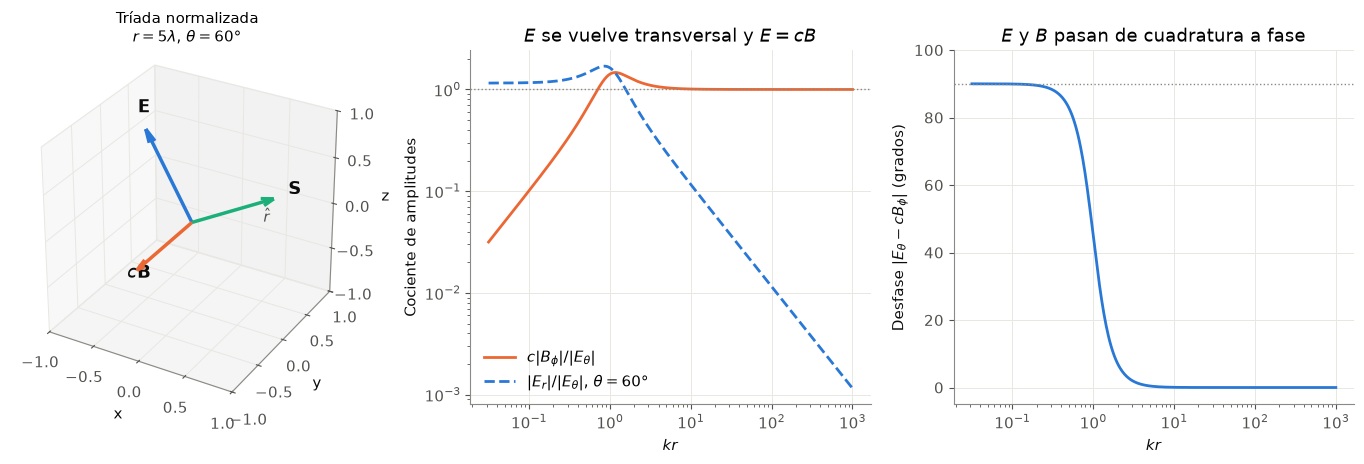

In [28]:
TH = np.radians(60)
fig = plt.figure(figsize=(14, 4.6))
ax3 = fig.add_subplot(131, projection="3d")
E_v, B_v, S_v, rh = triada(5 * L, TH)
for v, col, nom in zip((E_v, B_v, S_v), (AZUL, NARANJA, VERDE), ("$\\mathbf{E}$", "$c\\mathbf{B}$", "$\\mathbf{S}$")):
    u = v / np.linalg.norm(v)
    ax3.quiver(0, 0, 0, *u, color=col, lw=2.5, arrow_length_ratio=0.14)
    ax3.text(*(1.17 * u), nom, color=TINTA, fontsize=13)
ax3.text(*(0.72 * rh + np.array([0.14, 0, -0.14])), "$\\hat r$", color="#52514e")
ax3.set(xlim=(-1, 1), ylim=(-1, 1), zlim=(-1, 1), xlabel="x", ylabel="y", zlabel="z", box_aspect=(1, 1, 1))
ax3.set_title("Tríada normalizada\n$r=5\\lambda$, $\\theta=60°$", fontsize=11)

x = np.logspace(-1.5, 3, 500)
Fe, Fb = fasores(x)
ax = fig.add_subplot(132)
ax.loglog(x, np.abs(Fb) / np.abs(Fe), color=NARANJA, label="$c|B_\\phi|/|E_\\theta|$")
ax.loglog(x, np.abs(2 * np.cos(TH) * (1 / x**3 + 1j / x**2)) / (np.sin(TH) * np.abs(Fe)),
          color=AZUL, ls="--", label="$|E_r|/|E_\\theta|$, $\\theta=60°$")
ax.axhline(1, color=GRIS, lw=1, ls=":")
ax.set(xlabel="$kr$", ylabel="Cociente de amplitudes", title="$E$ se vuelve transversal y $E=cB$")
ax.legend()

ax = fig.add_subplot(133)
ax.semilogx(x, np.abs(np.degrees(np.angle(Fb / Fe))), color=AZUL)
ax.axhline(90, color=GRIS, lw=1, ls=":")
ax.set(xlabel="$kr$", ylabel="Desfase $|E_\\theta - cB_\\phi|$ (grados)", ylim=(-5, 100),
       title="$E$ y $B$ pasan de cuadratura a fase")
fig.tight_layout()
guardar(fig, "04_orientacion_EB.png")

### Vector de Poynting
Muestra la dirección y la magnitud de $\mathbf{S}$ en un instante (fila superior) y de su promedio temporal $\langle\mathbf{S}\rangle$ (fila inferior), en las tres regiones. Las flechas tienen longitud fija: la magnitud se lee en el color.

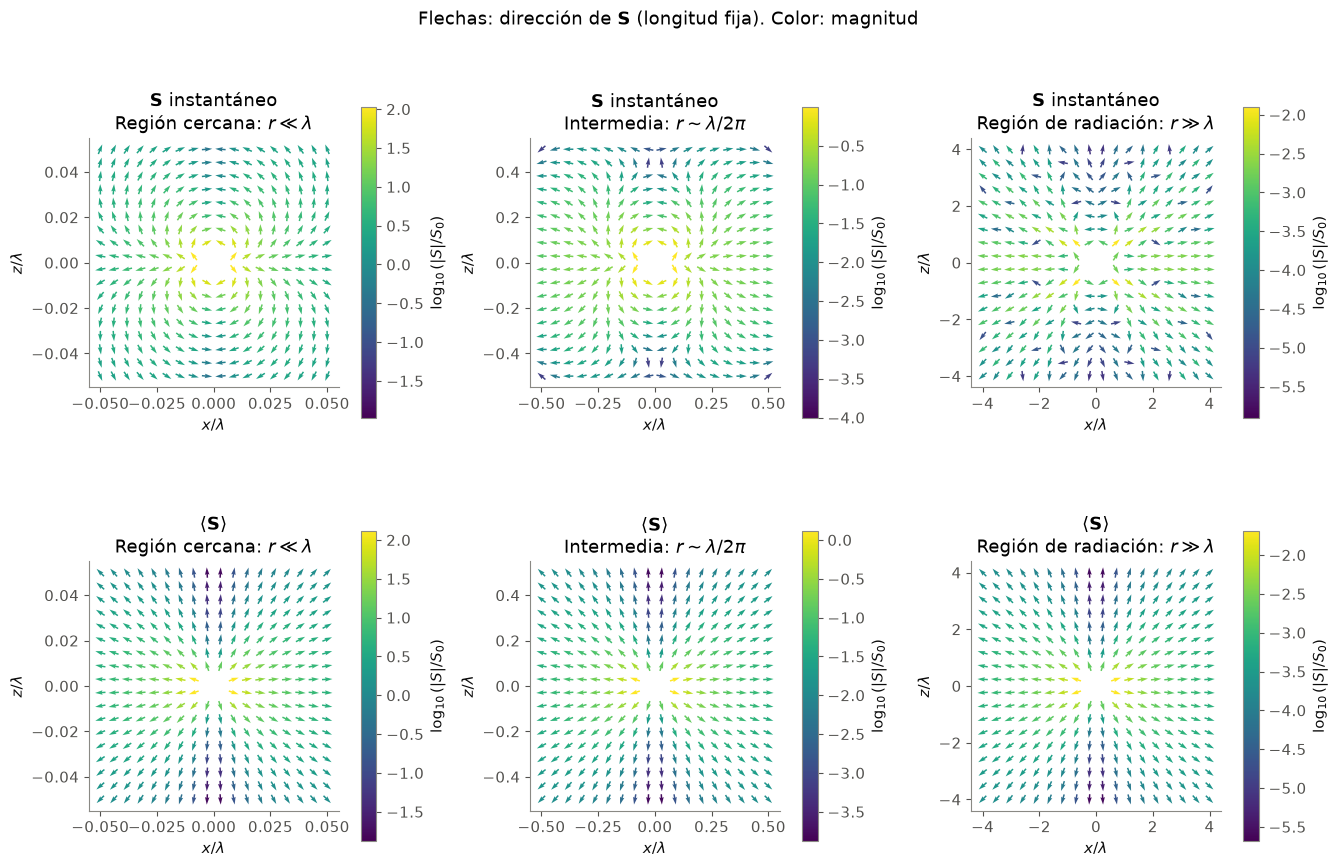

In [29]:
fig, axs = plt.subplots(2, 3, figsize=(13.5, 9))
for j, (titulo, R) in enumerate(REGIONES):
    g = np.linspace(-R, R, 18)  # número par: ningún punto cae sobre el eje, donde S = 0
    P, Z = np.meshgrid(g, g)
    r = np.hypot(P, Z)
    fuera = r > 0.15 * R
    P, Z, r = P[fuera], Z[fuera], r[fuera]
    th, sg, x = np.arctan2(np.abs(P), Z), np.sign(P) + (P == 0), L * r
    for i, (Sr, St, et) in enumerate([
        (*poynting(x, th, WT), "$\\mathbf{S}$ instantáneo"),
        (*poynting_promedio(x, th), "$\\langle\\mathbf{S}\\rangle$"),
    ]):
        Sp = sg * (Sr * np.sin(th) + St * np.cos(th))
        Sz = Sr * np.cos(th) - St * np.sin(th)
        m = np.hypot(Sp, Sz)
        ax = axs[i, j]
        lm = np.log10(m)
        q = ax.quiver(P, Z, Sp / m, Sz / m, lm, cmap="viridis", scale=24, width=0.006,
                      pivot="mid", clim=(lm.max() - 4, lm.max()))
        fig.colorbar(q, ax=ax, shrink=0.8, pad=0.07).set_label("$\\log_{10}(|S|/S_0)$")
        ax.set_aspect("equal")
        ax.grid(False)
        ax.set(title=f"{et}\n{titulo}", xlabel="$x/\\lambda$", ylabel="$z/\\lambda$")
        ax.set_xticks([-R, -R / 2, 0, R / 2, R])
fig.suptitle("Flechas: dirección de $\\mathbf{S}$ (longitud fija). Color: magnitud", y=0.995)
fig.tight_layout()
guardar(fig, "05_poynting_mapas.png")

### Energía que atraviesa una esfera
Grafica durante un periodo la potencia que cruza una esfera de radio $r$, normalizada con su promedio. Compara el vaivén de energía cerca del dipolo con el flujo hacia afuera en la región de radiación.

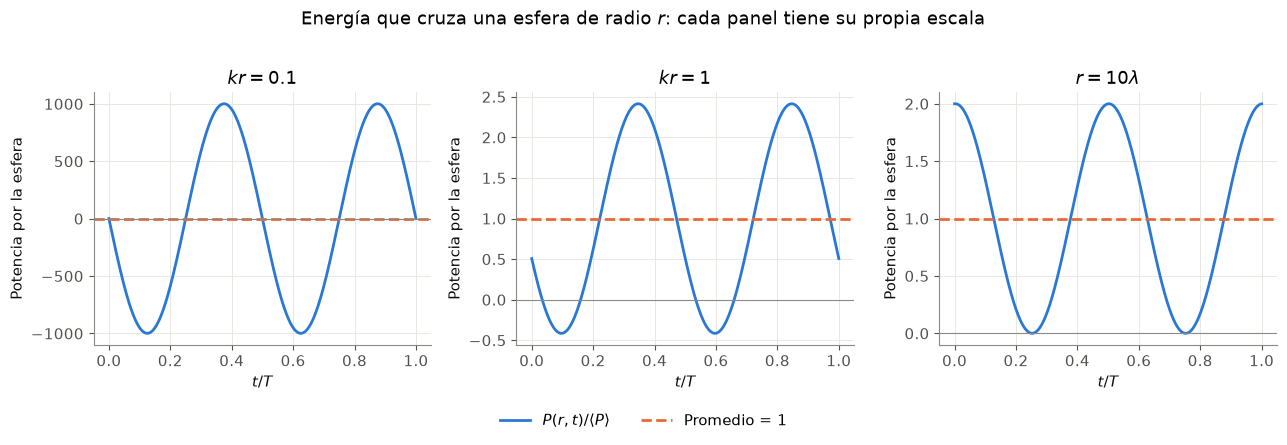

In [30]:
fases = np.linspace(0, 2 * np.pi, 720)
fig, axs = plt.subplots(1, 3, figsize=(13, 3.9))
for ax, x0, nom in zip(axs, (0.1, 1.0, 10 * L), ("$kr=0.1$", "$kr=1$", "$r=10\\lambda$")):
    ax.plot(fases / (2 * np.pi), potencia_esfera(x0, fases), color=AZUL, label="$P(r,t)/\\langle P\\rangle$")
    ax.axhline(1, color=NARANJA, ls="--", label="Promedio = 1")
    ax.axhline(0, color=GRIS, lw=0.8)
    ax.set(xlabel="$t/T$", ylabel="Potencia por la esfera", title=nom)
h, l = axs[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.09))
fig.suptitle("Energía que cruza una esfera de radio $r$: cada panel tiene su propia escala", y=1.02)
fig.tight_layout()
guardar(fig, "06_potencia_esfera.png")

### Patrón angular de radiación
Representa $dP/d\Omega \propto \sin^2\theta$ en un diagrama polar y en 3D. La potencia es máxima en el ecuador y nula sobre el eje del dipolo.

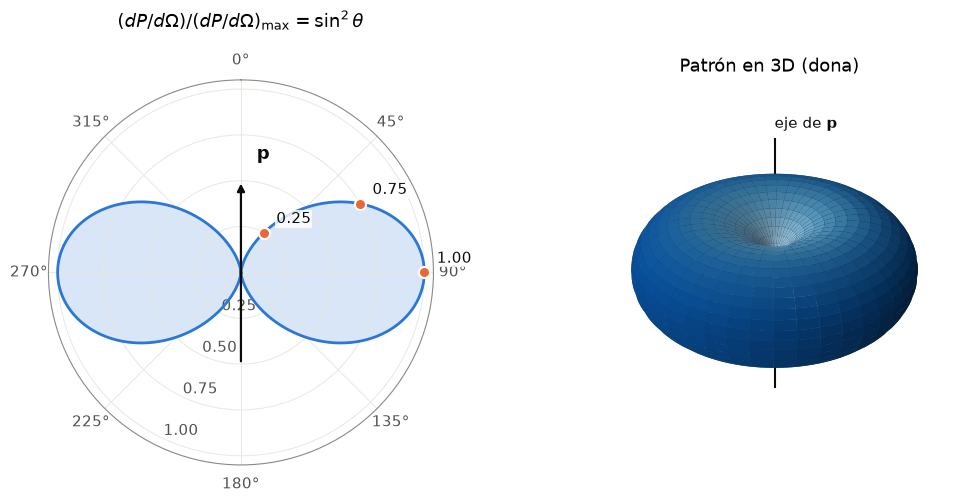

In [31]:
th = np.linspace(0, 2 * np.pi, 721)
fig = plt.figure(figsize=(12.5, 5))
ax = fig.add_subplot(121, projection="polar")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.plot(th, np.sin(th) ** 2, color=AZUL)
ax.fill(th, np.sin(th) ** 2, color=AZUL, alpha=0.18)
angs = [30, 60, 90]
a = np.radians(angs)
ax.plot(a, np.sin(a) ** 2, "o", color=NARANJA, ms=8, mec="white", mew=1.5)
for g, v in zip(angs, np.sin(a) ** 2):
    ax.annotate(f"{v:.2f}", (np.radians(g), v), textcoords="offset points", xytext=(9, 7), color=TINTA,
                bbox=dict(fc="white", ec="none", pad=0.8, alpha=0.8))
ax.annotate("", (0, 0.5), (np.pi, 0.5), arrowprops=dict(arrowstyle="-|>", color=TINTA, lw=1.6))
ax.text(np.radians(8), 0.62, "$\\mathbf{p}$", color=TINTA, fontsize=13)
ax.set_rticks([0.25, 0.5, 0.75, 1])
ax.set_rlabel_position(205)
ax.set_title("$(dP/d\\Omega)/(dP/d\\Omega)_{\\max}=\\sin^2\\theta$", pad=18)

ax = fig.add_subplot(122, projection="3d")
t, f = np.meshgrid(np.linspace(0, np.pi, 90), np.linspace(0, 2 * np.pi, 120))
r = np.sin(t) ** 2
ax.plot_surface(r * np.sin(t) * np.cos(f), r * np.sin(t) * np.sin(f), r * np.cos(t),
                facecolors=plt.cm.Blues(0.25 + 0.65 * r), linewidth=0, antialiased=True, shade=True)
ax.plot([0, 0], [0, 0], [-1, 1], color=TINTA, lw=1.5)
ax.text(0, 0, 1.08, "eje de $\\mathbf{p}$", color=TINTA)
ax.set(xlim=(-0.8, 0.8), ylim=(-0.8, 0.8), zlim=(-0.8, 0.8), box_aspect=(1, 1, 1))
ax.set_axis_off()
ax.set_title("Patrón en 3D (dona)")
guardar(fig, "07_patron_radiacion.png")

### Valores numéricos
Imprime datos para usar en el informe: desfase y cociente entre $E$ y $B$, valores relativos de $dP/d\Omega$ y comparación de $\mathbf{S}$ en un punto cercano y otro lejano.

In [32]:
print("4.2 Patrón angular: r^2<S_r> relativo, en r = 10 lambda")
print("theta   relativo   sin^2(theta)")
x0 = 10 * L
ref = x0**2 * poynting_promedio(x0, np.pi / 2)[0]
for g in [0, 15, 30, 45, 60, 75, 90]:
    t = np.radians(g)
    print(f"{g:5d}   {abs(x0**2 * poynting_promedio(x0, t)[0] / ref):8.4f}   {np.sin(t)**2:8.4f}")

print("\n4.3 Puntos en theta = 90 grados, unidades de S0")
fases = 2 * np.pi * np.arange(3600) / 3600
medias = []
for nom, x0 in [("cercano, kr = 0.1", 0.1), ("radiación, r = 10 lambda", 10 * L)]:
    Sr, St = poynting_promedio(x0, np.pi / 2)
    inst = poynting(x0, np.pi / 2, fases)[0]
    medias.append(Sr)
    print(f"{nom}\n  <S_r> = {Sr:.5e}\n  <S_theta> = {St:.5e}")
    print(f"  S_r instantáneo: de {inst.min():.5e} a {inst.max():.5e}")
    print(f"  |S_r|máx/<S_r> = {np.abs(inst).max() / Sr:.5e}")
    print(f"  P promedio por esfera/<P> = {np.mean(potencia_esfera(x0, fases)):.6f}")
print(f"<S> cercano/<S> radiación = {medias[0] / medias[1]:.5e}")

print("\n4.1 Relación entre E y B en theta = 90 grados")
for nom, x0 in [("kr = 0.1", 0.1), ("kr = 1", 1.0), ("r = 5 lambda", 5 * L)]:
    Fe, Fb = fasores(x0)
    print(f"{nom}: c|B|/|E| = {abs(Fb) / abs(Fe):.4f}, desfase = {abs(np.degrees(np.angle(Fb / Fe))):.3f} grados")

E_v, B_v, S_v, rh = triada(5 * L, np.radians(60))
print(f"\nr = 5 lambda, theta = 60: E.B = {np.dot(E_v, B_v):.2e}, "
      f"ángulo entre S y r = {np.degrees(np.arccos(np.dot(S_v, rh) / np.linalg.norm(S_v))):.4f} grados")

4.2 Patrón angular: r^2<S_r> relativo, en r = 10 lambda
theta   relativo   sin^2(theta)
    0     0.0000     0.0000
   15     0.0670     0.0670
   30     0.2500     0.2500
   45     0.5000     0.5000
   60     0.7500     0.7500
   75     0.9330     0.9330
   90     1.0000     1.0000

4.3 Puntos en theta = 90 grados, unidades de S0
cercano, kr = 0.1
  <S_r> = 5.00000e+01
  <S_theta> = 7.61864e-28
  S_r instantáneo: de -4.99500e+04 a 5.00500e+04
  |S_r|máx/<S_r> = 1.00100e+03
  P promedio por esfera/<P> = 1.000000
radiación, r = 10 lambda
  <S_r> = 1.26651e-04
  <S_theta> = -5.50401e-39
  S_r instantáneo: de 1.09793e-11 a 2.53303e-04
  |S_r|máx/<S_r> = 2.00000e+00
  P promedio por esfera/<P> = 1.000000
<S> cercano/<S> radiación = 3.94784e+05

4.1 Relación entre E y B en theta = 90 grados
kr = 0.1: c|B|/|E| = 0.1010, desfase = 89.943 grados
kr = 1: c|B|/|E| = 1.4142, desfase = 45.000 grados
r = 5 lambda: c|B|/|E| = 1.0010, desfase = 0.002 grados

r = 5 lambda, theta = 60: E.B = 0.00e+00, 

### Explorador interactivo
Permite mover dos deslizadores: `t_T` cambia el instante como fracción del periodo y `log10_R` cambia el tamaño de la región mostrada, desde $R = 0.01\lambda$ hasta $R = 10\lambda$.

In [33]:
def explorar(t_T=0.0, log10_R=0.0):
    R = 10**log10_R
    g = np.linspace(-R, R, 300)
    P, Z = np.meshgrid(g, g)
    r = np.maximum(np.hypot(P, Z), 0.08 * R)
    x, th = L * r, np.arctan2(np.abs(P), Z)
    wt = 2 * np.pi * t_T
    cB = campos(x, th, wt)[2] * (np.sign(P) + (P == 0)) * x
    v = np.percentile(np.abs(cB), 97) or 1.0
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.pcolormesh(P, Z, cB, cmap="RdBu_r", vmin=-v, vmax=v, shading="auto")
    Psi = funcion_lineas_E(x, th, wt)
    m = np.percentile(np.abs(Psi), 98)
    ax.contour(P, Z, Psi, levels=np.linspace(-m, m, 16), colors="k", linewidths=0.7, linestyles="solid")
    ax.grid(False)
    ax.set(aspect="equal", xlabel="$x/\\lambda$", ylabel="$z/\\lambda$",
           title=f"Líneas de E y $kr\\,cB_y$  (R = {R:.3g} λ, kR = {L * R:.3g})")
    plt.show()


interact(explorar,
         t_T=FloatSlider(min=0, max=1, step=0.02, value=0, continuous_update=False),
         log10_R=FloatSlider(min=-2, max=1, step=0.1, value=0, continuous_update=False));

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='t_T', max=1.0, step=0.02), …